# Monte Carlo disorder models, reference scattering, structure pictures and magnetism (Package D)

This notebook walks through the Package D additions on data committed to this repository; it runs without
DISCUS and writes only to a temporary folder.

1. **Reference scattering** — an independent direct-sum structure factor: textbook checks, then the comparison with
   real DISCUS 6.23.01 intensities from the pre-registered probe.
2. **Structure pictures** — atoms, displacement arrows and neighbor bonds in true geometry; export for viewers.
3. **Monte Carlo with DISCUS MMC** — configure a run in Python, read the macro, and analyse a real engine run:
   feedback history, acceptance, target vs achieved, and an independent measurement.
4. **Magnetic scattering (experimental)** — what DISCUS does not do, and a small analytical reference.

Details: `docs/REFERENCE_SCATTERING.md`, `docs/STRUCTURE_VIZ.md`, `docs/MONTE_CARLO.md`, `docs/MC_FACTS.md`,
`docs/MAGNETIC_SCATTERING.md`.

In [1]:
from pathlib import Path
import os, sys, shutil, tempfile, hashlib
sys.path.insert(0, str(Path.cwd().parent))
os.chdir(Path.cwd().parent)

import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 72
from discuspdf import Lattice, Structure, ScatteringFactors, read_stru, label_sites_by_slot, neighbor_list, repeat
from discuspdf import reference_scattering as ref

TMP = Path(tempfile.mkdtemp(prefix="nb10_"))
D_REF = Path("benchmarks/discus_6_23_01/d_reference")
D_MC = Path("benchmarks/discus_6_23_01/d_mc_probes")

## 1. Reference scattering

`F(Q) = Σ occ·f(s)·e^{−Bs²}·e^{+iQ·r}` with Q = 2π·hkl·B (parent-cell r.l.u.) and s = |Q|/4π. Scattering factors
always carry a source. First two textbook cases: two atoms give `f₁² + f₂² + 2f₁f₂cos(Q·d)`, and a perfect crystal
of N cells gives the Laue function with N² peaks.

two atoms: max |ref − formula| = 2.842170943040401e-14


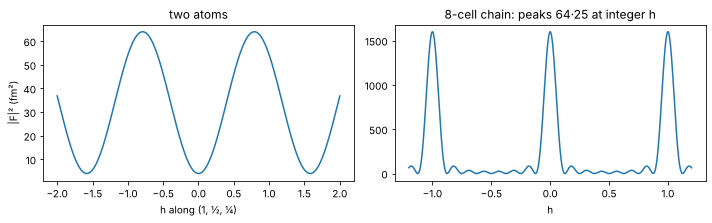

In [2]:
fac = ScatteringFactors.neutron({"A": 5.0, "B": -3.0}, source="toy values (fm)")
lat = Lattice.from_parameters(5, 5, 5, 90, 90, 90)
pair = Structure(lat, ["A", "B"], [[0, 0, 0], [0.37, 0.22, 0.61]], model="configuration")
h = np.linspace(-2, 2, 401)
hkl = np.column_stack([h, 0.5 * h, 0.25 * h])
I_pair = ref.intensity(pair, fac, hkl=hkl)
Q = ref.scattering_vectors(pair, hkl=hkl)
d = pair.cartesian[1] - pair.cartesian[0]
print("two atoms: max |ref − formula| =", np.abs(I_pair - (25 + 9 - 30 * np.cos(Q @ d))).max())

chain = repeat(Structure(Lattice.from_parameters(3, 3, 3, 90, 90, 90), ["A"], [[0, 0, 0]],
                         model="configuration"), (8, 1, 1)).structure
h1 = np.linspace(-1.2, 1.2, 1201)
I_chain = ref.intensity(chain, fac, hkl=np.column_stack([h1, 0 * h1, 0 * h1]))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(h, I_pair); ax[0].set(xlabel="h along (1, ½, ¼)", ylabel="|F|² (fm²)", title="two atoms")
ax[1].plot(h1, I_chain); ax[1].set(xlabel="h", title="8-cell chain: peaks 64·25 at integer h")
plt.tight_layout()

### Against DISCUS 6.23.01

The probe ran DISCUS on a 4×4×4 fcc Cu₀.₇₅Au₀.₂₅ crystal with B ≠ 0 (X-ray and neutron, total and Bragg-subtracted).
DISCUS evaluates the X-ray factor *and* the isotropic Debye–Waller factor at s rounded to 0.001 Å⁻¹; emulating that
("engine" mode, as in `analyze.py`) the reference agrees to ~1e-15, while the exact-s physics differs by ~1e-3.
Here: the Bragg-subtracted X-ray intensity in the l = 0 layer.

physics  relative L2 difference from DISCUS: 8.55e-04
engine   relative L2 difference from DISCUS: 5.09e-15


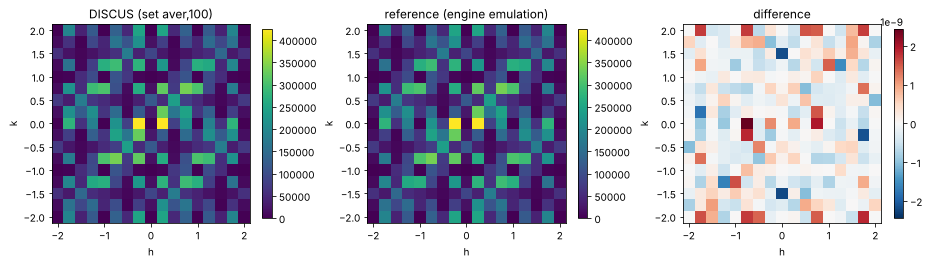

In [3]:
import importlib.util
spec = importlib.util.spec_from_file_location("d_ref_analyze", D_REF / "analyze.py")
an = importlib.util.module_from_spec(spec); spec.loader.exec_module(an)
from discuspdf.discus_output import read_discus_volume

EV = D_REF / "evidence/20261101T221751Z_LAPTOP-NGU3BT0N/work"
vol = read_discus_volume(EV / "cuau_x_dif_c4.h5")
st = label_sites_by_slot(read_stru(EV / "cuau.stru").structure)
idx = np.indices(vol.values.shape).transpose(1, 2, 3, 0)
hkl = np.einsum("ab,ijkb->ijka", vol.increments, idx) + vol.corner
bmap = an.species_b(st)
for mode in ("physics", "engine"):
    f, dw = an.factors("xray", mode, bmap)
    I = ref.diffuse_intensity(st, f, hkl=hkl, debye_waller=dw)
    print(f"{mode:8s} relative L2 difference from DISCUS: {np.linalg.norm(vol.values - I) / np.linalg.norm(I):.2e}")
f, dw = an.factors("xray", "engine", bmap)
I = ref.diffuse_intensity(st, f, hkl=hkl[:, :, :1], debye_waller=dw)[:, :, 0]
dh, dk = vol.increments[0, 0] / 2, vol.increments[1, 1] / 2      # pixel edges
ext = [hkl[0, 0, 0, 0] - dh, hkl[-1, 0, 0, 0] + dh, hkl[0, 0, 0, 1] - dk, hkl[0, -1, 0, 1] + dk]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, data, title in zip(ax, (vol.values[:, :, 0], I, vol.values[:, :, 0] - I),
                          ("DISCUS (set aver,100)", "reference (engine emulation)", "difference")):
    lim = np.abs(data).max() if title == "difference" else None
    im = a.imshow(data.T, origin="lower", extent=ext, cmap="RdBu_r" if lim else "viridis",
                  vmin=-lim if lim else None, vmax=lim)
    a.set(title=title, xlabel="h", ylabel="k"); plt.colorbar(im, ax=a, shrink=0.8)
plt.tight_layout()

## 2. Structure pictures

The displaced monoclinic crystal of the probe (β = 103°, 3×3×3 cells, σ = 0.05 Å). Displacements are drawn against
the undisplaced sites (matched by site and cell, minimum image), ×10 as stated in the title; bonds show the first
neighbor shell of the ideal crystal. Nothing is wrapped or rotated.

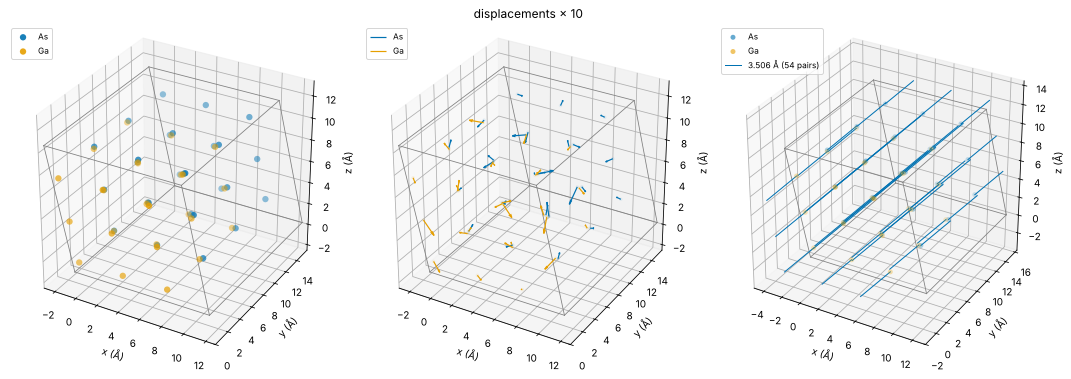

In [4]:
from discuspdf.structure_viz import plot_structure, plot_displacements, plot_bonds, export_structure

mono = label_sites_by_slot(read_stru(EV / "mono.stru").structure)
ideal = mono.replace(frac=(mono.cell_index + np.array([[0.05, 0.1, 0.2], [0.55, 0.62, 0.71]] * (mono.n_atoms // 2)))
                     / mono.supercell, min_separation=None)
fig = plt.figure(figsize=(15, 5))
plot_structure(mono, ax=fig.add_subplot(131, projection="3d"))
plot_displacements(mono, ideal, scale=10, ax=fig.add_subplot(132, projection="3d"))
plot_bonds(neighbor_list(ideal, 4.0).select(shell=1), ax=fig.add_subplot(133, projection="3d"))
plt.tight_layout()

In [5]:
try:
    out = export_structure(mono, TMP / "mono.xyz", format="extxyz")   # read back and checked
    print("written and verified:", out.name)
except ImportError as exc:
    print("ASE not installed:", exc)

written and verified: mono.xyz


## 3. Monte Carlo with DISCUS MMC

`MCConfig` describes one run and renders the exact macro. Two engine facts matter for every run
(`docs/MC_FACTS.md`, confirmed by the probe): DISCUS accepts downhill moves always and uphill **and neutral** moves
with probability `1/(1+e^{ΔE/kT})` (heat bath, not Metropolis), and a run is only reproducible with an 8-value seed
on one thread — the API always writes both. This is the configuration of probe run r1: a simple cubic Cu₀.₅Au₀.₅
crystal driven to a nearest-neighbor correlation of −0.3.

In [6]:
from discuspdf.fourier_macro import Seed
from discuspdf.mc import MCConfig, MCRunner, Neighborhood, OccupationalTarget, Swap, Vector

six = Neighborhood(tuple(Vector(1, 1, t) for t in [(1, 0, 0), (-1, 0, 0), (0, 1, 0), (0, -1, 0), (0, 0, 1), (0, 0, -1)]))
cfg = MCConfig((six,), (OccupationalTarget(0, "Cu", "Au", correlation=-0.3),), (Swap(),),
               Seed((11, 22, 33, 44, 55, 66, 77, 88)), moves_per_atom=10, feedback_per_atom=1)
print(cfg.render("mc_in.stru", n_atoms=4096))
for c in cfg.cautions():
    print("caution:", c)

discus
seed 11,22,33,44,55,66,77,88
set parallel, useomp:off
read
  stru mc_in.stru
mmc
set vec, reset
set vec, 1, 1, 1, 1, 0, 0
set vec, 2, 1, 1, -1, 0, 0
set vec, 3, 1, 1, 0, 1, 0
set vec, 4, 1, 1, 0, -1, 0
set vec, 5, 1, 1, 0, 0, 1
set vec, 6, 1, 1, 0, 0, -1
set neig, rese
set neig, vec, 1, 2, 3, 4, 5, 6, number:1
set mode, 1.0, swchem, all
set target, 1, corr, Cu, Au, -0.3, 0.0, CORR
set temp, 1.0
set cyc, 40960
set feed, 4096
set output, feed:on, final:on
show
run
exit
save mc_out.stru
exit
exit

caution: acceptance is heat-bath for uphill and neutral moves (ΔE = 0 accepted with probability ½), not Metropolis


The engine run is committed (`d_mc_probes/evidence/run1`). `MCRunner.load` reads a run directory: it checks the
exit code, error lines, the number of moves and the output, then restores the supercell and species spelling that
DISCUS's `save` drops. Here a run directory is staged from the evidence, exactly as `execute` would leave it.

In [7]:
EVM = D_MC / "evidence/run1"
runner = MCRunner(TMP / "runs")
run = runner.prepare(cfg, read_stru(EVM / "work/cuau.stru").structure)
shutil.copy(EVM / "r1_occ_corr.log", run.directory / "run.log")
shutil.copy(EVM / "work/r1_occ_corr_out.stru", run.directory / "mc_out.stru")
res = runner.load(run, returncode=0)
print("status:", res.status)
for r in res.target_report(tol=0.02):
    print(f"target {r['target']:+.3f}  achieved {r['achieved']:+.3f}  reached={r['reached']}  pairs={r['pairs']}")
for m in res.measure():
    print(f"independent measurement: {m['value']:+.6f} over {m['pairs']} pairs (Package C pooled α {m['pooled_alpha']:+.6f})")

status: complete
target -0.300  achieved -0.306  reached=True  pairs=24576


independent measurement: -0.306315 over 24576 pairs (Package C pooled α -0.306315)


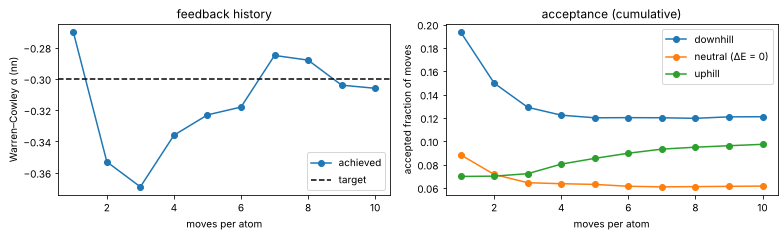

In [8]:
hist, acc = res.history(0), res.acceptance()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(hist[:, 0] / 4096, hist[:, 2], "o-", label="achieved")
ax[0].axhline(hist[0, 1], color="k", ls="--", label="target")
ax[0].set(xlabel="moves per atom", ylabel="Warren–Cowley α (nn)", title="feedback history"); ax[0].legend()
gen = acc[:, 0]
for k, name in zip((2, 3, 4), ("downhill", "neutral (ΔE = 0)", "uphill")):
    ax[1].plot(gen / 4096, acc[:, k] / gen, "o-", label=name)
ax[1].set(xlabel="moves per atom", ylabel="accepted fraction of moves", title="acceptance (cumulative)"); ax[1].legend()
plt.tight_layout()

Reproducibility and composition: the same run repeated (r1b) gave a byte-identical structure; the same seed on four
OpenMP threads (r1c, r1d) did not, and did 45 056 instead of 40 960 moves — which is why the API forces serial runs.

In [9]:
sha = dict(l.split()[::-1] for l in (EVM / "output_sha256.txt").read_text().splitlines())
print("serial repeat identical:", sha["r1_occ_corr_out.stru"] == sha["r1b_occ_corr_repeat_out.stru"])
print("4 threads, repeat identical:", sha["r1c_occ_corr_omp4_out.stru"] == sha["r1d_occ_corr_omp4_repeat_out.stru"])
print("composition in / out:", {s: int((res.structure.species == s).sum()) for s in ("Cu", "Au")})

serial repeat identical: True
4 threads, repeat identical: False
composition in / out: {'Cu': 2048, 'Au': 2048}


A run that does **not** reach its target is reported as such. In the live test `c1` (a feedback target of −0.4 on the
eight unlike neighbors of a B2 cell, competing with a fixed energy on the same-site neighbors), DISCUS finished all
moves and the run is `complete`, but the target was missed:

In [10]:
import json
c1 = next((D_MC / "evidence/live_generated").glob("c1_b2_two_targets_result.json"))
for r in json.loads(c1.read_text())["report"]:
    print(f"nb {r['neighborhood']} {r['mode']:4s} target {r['target']:+.3f} achieved {r['achieved']:+.3f} reached={r['reached']}")

nb 1 CORR target -0.400 achieved -0.507 reached=False
nb 2 ENER target +0.000 achieved +0.434 reached=None


## 4. Magnetic scattering (experimental)

DISCUS 6.23.01 stores a moment per atom but computes no magnetic scattering, and its `.stru` files drop moments.
`discuspdf.magnetic_reference` is a small, explicitly experimental reference (unpolarised neutrons, dipole
approximation, `p = γr₀/2 = 2.695 fm`, Cartesian moments in μB). An antiferromagnetic chain scatters at half-integer
h; a moment parallel to Q does not scatter at all — also in a skewed cell, where Javelin's projection fails.

μ ∥ Q in a triclinic cell: 7.164128949689325e-31
Q = 0 is masked: (array([nan]), array([False]))


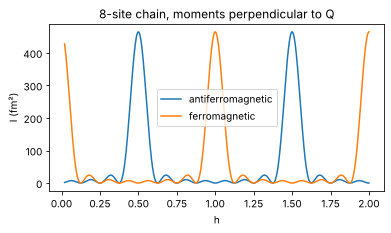

In [11]:
from discuspdf.magnetic_reference import magnetic_intensity, P_MAGNETIC_FM

one = lambda q: np.ones_like(np.asarray(q, float))      # form factor 1: geometry only
a, N = 3.0, 8
latc = Lattice.from_parameters(a, 10, 10, 90, 90, 90)
r = np.column_stack([np.arange(N) * a, np.zeros(N), np.zeros(N)])
mu = np.zeros((N, 3)); mu[:, 2] = np.where(np.arange(N) % 2 == 0, 1.0, -1.0)
h = np.linspace(0.02, 2.0, 600)
I_af, ok = magnetic_intensity(r, mu, latc.hkl_to_q(np.column_stack([h, 0 * h, 0 * h])), one)
I_fm, _ = magnetic_intensity(r, np.abs(mu), latc.hkl_to_q(np.column_stack([h, 0 * h, 0 * h])), one)
plt.figure(figsize=(6, 3)); plt.plot(h, I_af, label="antiferromagnetic"); plt.plot(h, I_fm, label="ferromagnetic")
plt.xlabel("h"); plt.ylabel("I (fm²)"); plt.legend(); plt.title("8-site chain, moments perpendicular to Q")

tri = Lattice.from_parameters(5.3, 6.1, 4.7, 81, 97, 113)
q = tri.hkl_to_q([[1, 2, -1]])
print("μ ∥ Q in a triclinic cell:", magnetic_intensity([[0, 0, 0]], 1.7 * q / np.linalg.norm(q), q, one)[0][0])
print("Q = 0 is masked:", magnetic_intensity([[0, 0, 0]], [[0, 1, 0]], [[0, 0, 0]], one))